## WorldTrace Geographic Group Differences (Flag 4)

### Dataset Overview
A 48-record comparison with four coarse start-region groups and trajectory-level movement, speed, distance, route-indirectness, time, and context fields.

The notebook exposes the primary analysis table and trajectory_points.csv as the supporting point table.

Goal: Identify movement groups among the provided trajectories based on their regions and analyze the resulting groups.

Role: NYC mobility insight analyst


Category: Geographic Group Differences

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "04_geographic_group_differences.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)


Synthetic reconstructed GPS and timestamps are provided in trajectory_points.csv. All 48 distance profiles have been revised to reflect the requested regional distance scales, preserving trajectory IDs, start positions, mode shares, mean speeds and route-indirectness scores. These are not recovered WorldTrace observations or road-matched paths. See reconstruction_provenance.json.

### **Question 1**: How many trajectories are represented in each observed geographic group?

#### Analysis action

Keep the group counts visible when interpreting regional differences; the comparison describes the provided trajectories rather than city-wide frequencies.

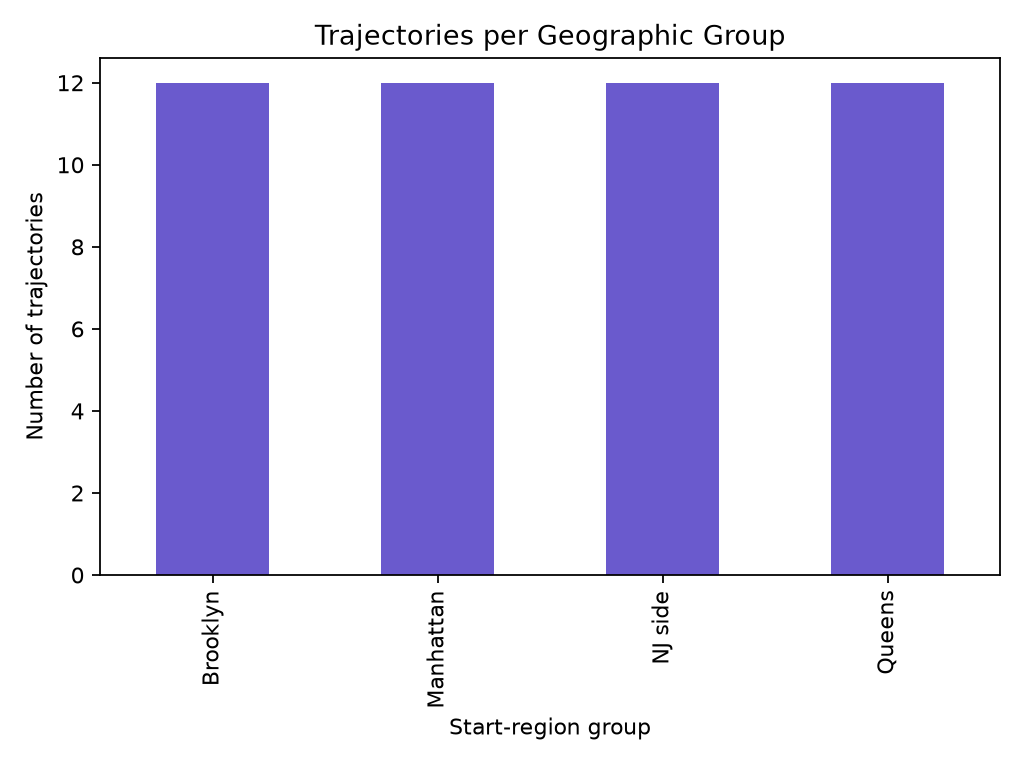

In [ ]:
import matplotlib.pyplot as plt

order = ["Brooklyn", "Manhattan", "NJ side", "Queens"]
df["start_region_coarse"].value_counts().reindex(order).plot(kind="bar", color="slateblue")
plt.title("Trajectories per Geographic Group")
plt.xlabel("Start-region group")
plt.ylabel("Number of trajectories")
plt.tight_layout()
plt.show()

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "The provided trajectories form four equally sized start-region groups: Brooklyn, Manhattan, NJ side, and Queens each contribute 12 trajectories.",
  "insight_value": {
    "group_counts": {
      "Brooklyn": 12,
      "Manhattan": 12,
      "NJ side": 12,
      "Queens": 12
    }
  },
  "plot": {
    "plot_type": "bar",
    "title": "Trajectories per Geographic Group",
    "x_axis": {
      "name": "Start-region group",
      "description": "The coarse start-region label."
    },
    "y_axis": {
      "name": "Number of trajectories",
      "description": "The number of provided trajectories in each group."
    },
    "description": "The group counts establish the regional movement groups before their trajectory summaries are compared.",
    "file": "notebook_plots/q1_1.png"
  },
  "question": "How many trajectories are represented in each observed geographic group?",
  "actionable_insight": "Keep the group counts visible when interpreting regional differences; the comparison describes the provided trajectories rather than city-wide frequencies.",
  "code": "import matplotlib.pyplot as plt\n\norder = [\"Brooklyn\", \"Manhattan\", \"NJ side\", \"Queens\"]\ndf[\"start_region_coarse\"].value_counts().reindex(order).plot(kind=\"bar\", color=\"slateblue\")\nplt.title(\"Trajectories per Geographic Group\")\nplt.xlabel(\"Start-region group\")\nplt.ylabel(\"Number of trajectories\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: How do the observed geographic groups differ in trajectory distance and route indirectness?

#### Analysis action

Compare distance and route indirectness as separate regional summaries; a group can have longer trajectories without having the most indirect routes.

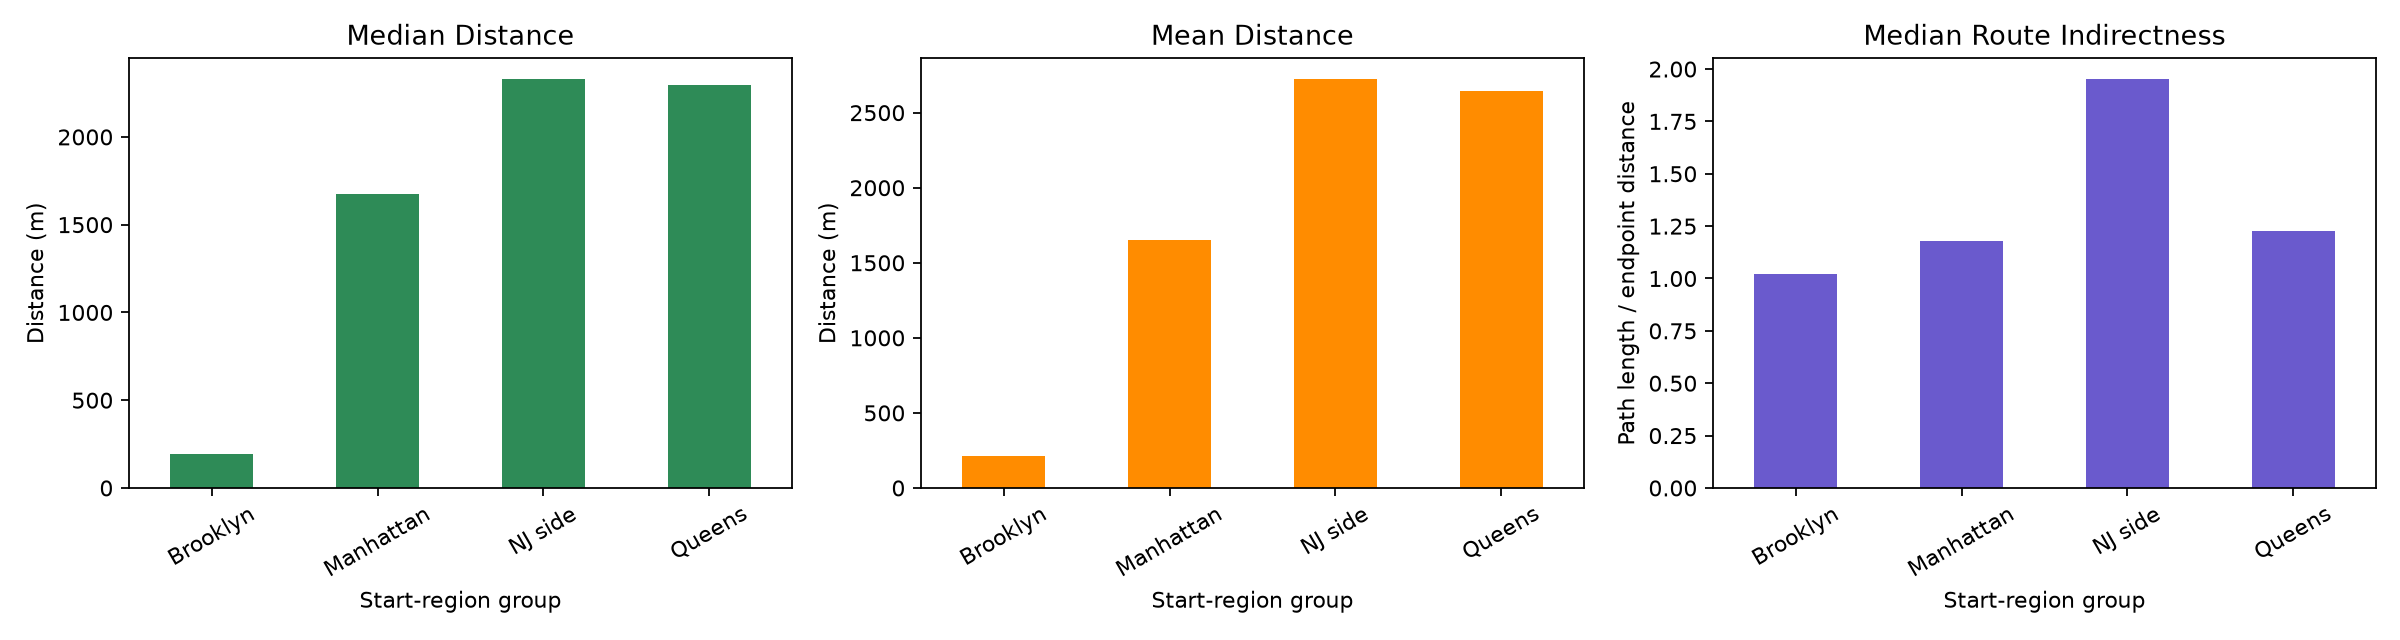

In [ ]:
import matplotlib.pyplot as plt

order = ["Brooklyn", "Manhattan", "NJ side", "Queens"]
grouped = df.groupby("start_region_coarse").agg(
 median_distance_m=("distance_meters", "median"),
 mean_distance_m=("distance_meters", "mean"),
 median_route_indirectness=("detour_score", "median")
).reindex(order)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
grouped["median_distance_m"].plot(kind="bar", ax=axes[0], color="seagreen", title="Median Distance")
grouped["mean_distance_m"].plot(kind="bar", ax=axes[1], color="darkorange", title="Mean Distance")
grouped["median_route_indirectness"].plot(kind="bar", ax=axes[2], color="slateblue", title="Median Route Indirectness")
axes[0].set_ylabel("Distance (m)")
axes[1].set_ylabel("Distance (m)")
axes[2].set_ylabel("Path length / endpoint distance")
for ax in axes:
 ax.set_xlabel("Start-region group")
 ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "The geographic groups differ in their observed distance and route-indirectness summaries: NJ side and Queens have the largest median distances; NJ side has the highest median route-indirectness score; and Brooklyn has both the lowest average distance and the most direct routes.",
  "insight_value": {
    "median_distance_m": {
      "Brooklyn": 195.45,
      "Manhattan": 1676.25,
      "NJ side": 2332.25,
      "Queens": 2293.46
    },
    "mean_distance_m": {
      "Brooklyn": 210.1,
      "Manhattan": 1650.04,
      "NJ side": 2726.96,
      "Queens": 2644.83
    },
    "median_route_indirectness": {
      "Brooklyn": 1.021,
      "Manhattan": 1.18,
      "NJ side": 1.954,
      "Queens": 1.225
    }
  },
  "plot": {
    "plot_type": "multi_panel_bar",
    "title": "Distance and Route Indirectness by Start Region",
    "x_axis": {
      "name": "Start-region group",
      "description": "The coarse start-region label."
    },
    "y_axis": {
      "name": "Summary values",
      "description": "Median distance, mean distance, and median route-indirectness summaries by group."
    },
    "description": "Separate panels compare median distance, mean distance, and median route indirectness so that distance and route shape are not conflated.",
    "file": "notebook_plots/q2_1.png"
  },
  "question": "How do the observed geographic groups differ in trajectory distance and route indirectness?",
  "actionable_insight": "Compare distance and route indirectness as separate regional summaries; a group can have longer trajectories without having the most indirect routes.",
  "code": "import matplotlib.pyplot as plt\n\norder = [\"Brooklyn\", \"Manhattan\", \"NJ side\", \"Queens\"]\ngrouped = df.groupby(\"start_region_coarse\").agg(\n median_distance_m=(\"distance_meters\", \"median\"),\n mean_distance_m=(\"distance_meters\", \"mean\"),\n median_route_indirectness=(\"detour_score\", \"median\")\n).reindex(order)\n\nfig, axes = plt.subplots(1, 3, figsize=(15, 4))\ngrouped[\"median_distance_m\"].plot(kind=\"bar\", ax=axes[0], color=\"seagreen\", title=\"Median Distance\")\ngrouped[\"mean_distance_m\"].plot(kind=\"bar\", ax=axes[1], color=\"darkorange\", title=\"Mean Distance\")\ngrouped[\"median_route_indirectness\"].plot(kind=\"bar\", ax=axes[2], color=\"slateblue\", title=\"Median Route Indirectness\")\naxes[0].set_ylabel(\"Distance (m)\")\naxes[1].set_ylabel(\"Distance (m)\")\naxes[2].set_ylabel(\"Path length / endpoint distance\")\nfor ax in axes:\n ax.set_xlabel(\"Start-region group\")\n ax.tick_params(axis=\"x\", rotation=30)\nplt.tight_layout()\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: Which geographic group is walking-dominant, and how does its average trajectory distance compare with the other groups?

#### Analysis action

Use Brooklyn as the walking-dominant, short-distance group when interpreting the regional comparison, and consider movement mode alongside distance.

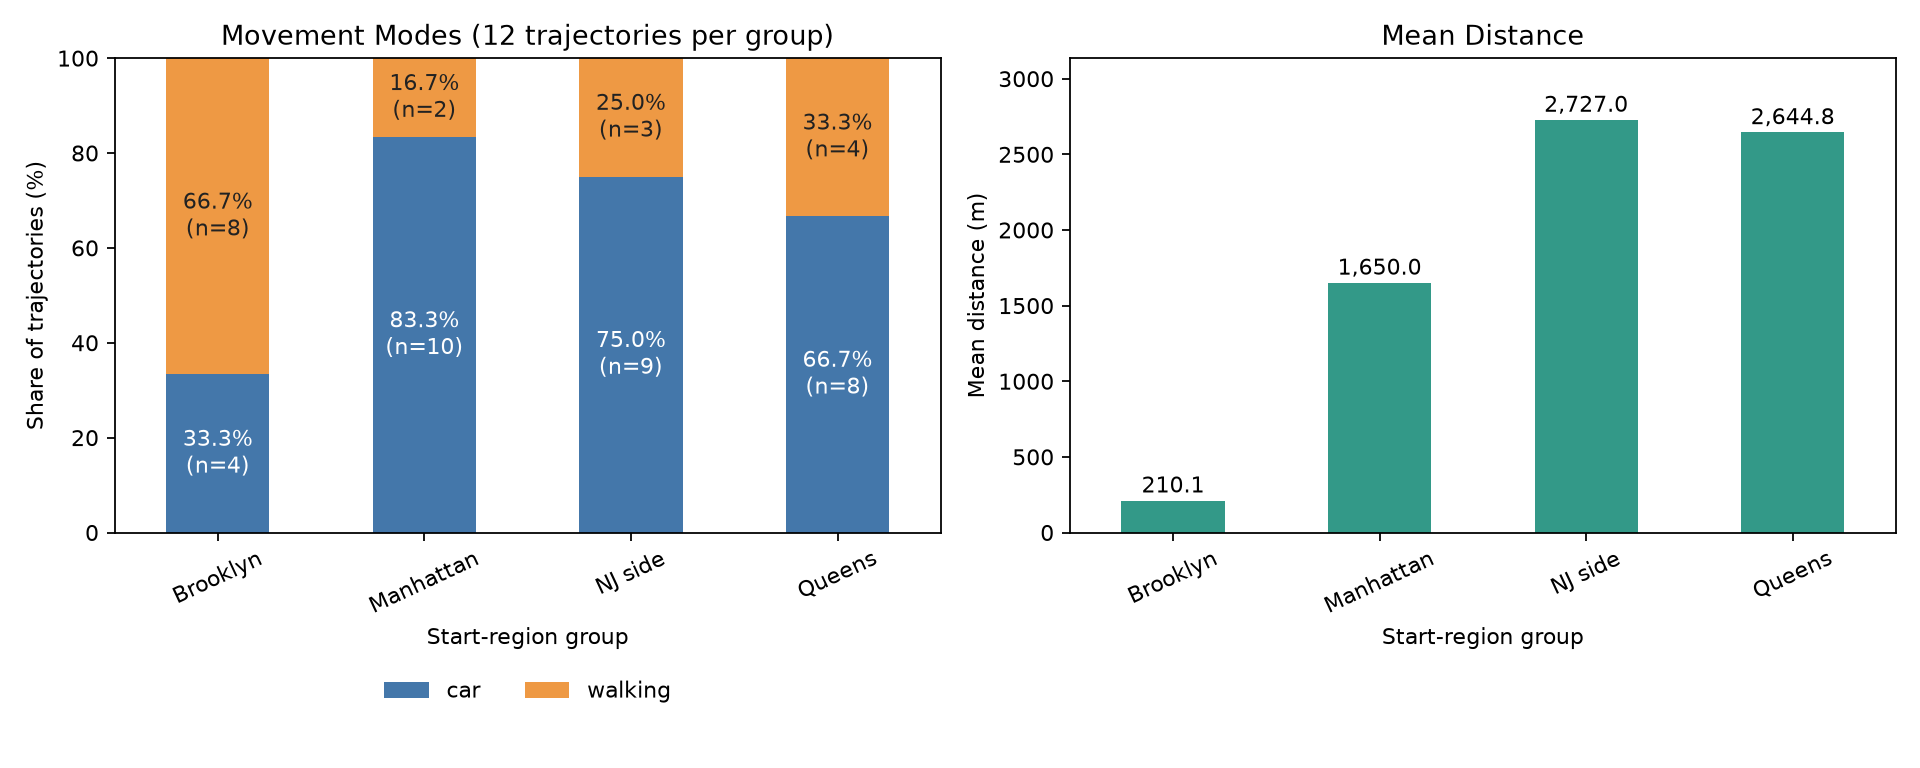

In [ ]:
import matplotlib.pyplot as plt

order = ["Brooklyn", "Manhattan", "NJ side", "Queens"]
mode_counts = df.groupby(["start_region_coarse", "travel_mode"]).size().unstack(fill_value=0).reindex(order)[["car", "walking"]]
shares = mode_counts.div(mode_counts.sum(axis=1), axis=0) * 100
mean_distance = df.groupby("start_region_coarse")["distance_meters"].mean().reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
shares.plot(kind="bar", stacked=True, ax=axes[0], color=["#4477aa", "#ee9944"], title="Movement Modes (12 trajectories per group)")
for j, region in enumerate(order):
    bottom = 0
    for mode in ["car", "walking"]:
        value = shares.loc[region, mode]
        axes[0].text(j, bottom + value / 2, f"{value:.1f}%\n(n={mode_counts.loc[region, mode]})", ha="center", va="center", color="white" if mode == "car" else "#222222", fontsize=10)
        bottom += value
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("Share of trajectories (%)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, frameon=False)
mean_distance.plot(kind="bar", ax=axes[1], color="#339988", title="Mean Distance")
axes[1].set_ylabel("Mean distance (m)")
for j, value in enumerate(mean_distance):
    axes[1].text(j, value + mean_distance.max() * 0.02, f"{value:,.1f}", ha="center", fontsize=10)
axes[1].set_ylim(0, mean_distance.max() * 1.15)
for ax in axes:
    ax.set_xlabel("Start-region group")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "In the Brooklyn group, most trajectories are walking trips, making it the only walking-dominant group; its average trajectory distance is also much shorter than that of the other groups.",
  "insight_value": {
    "mode_counts": {
      "Brooklyn": {
        "walking": 8,
        "car": 4
      },
      "Manhattan": {
        "walking": 2,
        "car": 10
      },
      "NJ side": {
        "walking": 3,
        "car": 9
      },
      "Queens": {
        "walking": 4,
        "car": 8
      }
    },
    "mean_distance_m": {
      "Brooklyn": 210.1,
      "Manhattan": 1650.04,
      "NJ side": 2726.96,
      "Queens": 2644.83
    },
    "mode_share_percent": {
      "Brooklyn": {
        "walking": 66.67,
        "car": 33.33
      },
      "Manhattan": {
        "walking": 16.67,
        "car": 83.33
      },
      "NJ side": {
        "walking": 25.0,
        "car": 75.0
      },
      "Queens": {
        "walking": 33.33,
        "car": 66.67
      }
    }
  },
  "plot": {
    "plot_type": "multi_panel_bar",
    "title": "Movement Mode and Mean Distance by Geographic Group",
    "x_axis": {
      "name": "Start-region group",
      "description": "The coarse start-region label."
    },
    "y_axis": {
      "name": "Mode share or mean distance",
      "description": "Percentage of trajectories by movement mode, and mean trajectory distance in meters."
    },
    "description": "The first panel shows mode shares and counts for each 12-trajectory group, including different car shares in Manhattan, NJ side and Queens; the second compares mean distance.",
    "file": "notebook_plots/q3_1.png"
  },
  "question": "Which geographic group is walking-dominant, and how does its average trajectory distance compare with the other groups?",
  "actionable_insight": "Use Brooklyn as the walking-dominant, short-distance group when interpreting the regional comparison, and consider movement mode alongside distance.",
  "code": "import matplotlib.pyplot as plt\n\norder = [\"Brooklyn\", \"Manhattan\", \"NJ side\", \"Queens\"]\nmode_counts = df.groupby([\"start_region_coarse\", \"travel_mode\"]).size().unstack(fill_value=0).reindex(order)[[\"car\", \"walking\"]]\nshares = mode_counts.div(mode_counts.sum(axis=1), axis=0) * 100\nmean_distance = df.groupby(\"start_region_coarse\")[\"distance_meters\"].mean().reindex(order)\nfig, axes = plt.subplots(1, 2, figsize=(12, 4.8))\nshares.plot(kind=\"bar\", stacked=True, ax=axes[0], color=[\"#4477aa\", \"#ee9944\"], title=\"Movement Modes (12 trajectories per group)\")\nfor j, region in enumerate(order):\n    bottom = 0\n    for mode in [\"car\", \"walking\"]:\n        value = shares.loc[region, mode]\n        axes[0].text(j, bottom + value / 2, f\"{value:.1f}%\\n(n={mode_counts.loc[region, mode]})\", ha=\"center\", va=\"center\", color=\"white\" if mode == \"car\" else \"#222222\", fontsize=10)\n        bottom += value\naxes[0].set_ylim(0, 100)\naxes[0].set_ylabel(\"Share of trajectories (%)\")\naxes[0].legend(loc=\"upper center\", bbox_to_anchor=(0.5, -0.27), ncol=2, frameon=False)\nmean_distance.plot(kind=\"bar\", ax=axes[1], color=\"#339988\", title=\"Mean Distance\")\naxes[1].set_ylabel(\"Mean distance (m)\")\nfor j, value in enumerate(mean_distance):\n    axes[1].text(j, value + mean_distance.max() * 0.02, f\"{value:,.1f}\", ha=\"center\", fontsize=10)\naxes[1].set_ylim(0, mean_distance.max() * 1.15)\nfor ax in axes:\n    ax.set_xlabel(\"Start-region group\")\n    ax.tick_params(axis=\"x\", rotation=25)\nplt.tight_layout()\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 4)

The provided trajectories form four equally sized regional groups. NJ side and Queens have the largest median distances, NJ side has the highest median route indirectness, and Brooklyn combines the shortest average distance with the most direct routes. Brooklyn is also the only walking-dominant group, so movement mode remains part of the regional comparison.